# PE2 – Oplossing (in de stijl van week 6 en week 7)

Doel: `status_type` reproduceren via clustering. Stappen: data inlezen → opkuisen → standaardiseren → PCA (week 7) → KMeans en DBSCAN (week 5–6) → vergelijken met een confusion matrix.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Data inlezen

`Live.xls` is eigenlijk een CSV-bestand, daarom gebruik ik `read_csv`.

In [3]:
data = pd.read_csv("Live.xls")
data.head()

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,246675545449582_1649696485147474,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,246675545449582_1649426988507757,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,246675545449582_1648730588577397,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,246675545449582_1648576705259452,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,246675545449582_1645700502213739,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


In [4]:
print(data.shape)
print(data.isna().sum())
print("Duplicaten:", data.duplicated().sum())

(7050, 16)
status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64
Duplicaten: 51


## 2. Opkuisen

- `Column1`–`Column4` zijn volledig leeg → droppen.
- `status_id` (uniek ID) en `status_published` (tijdstip) zijn tekst en zeggen niets over de inhoud van een post → droppen.
- Dubbele rijen verwijder ik, anders tellen die posts dubbel mee.
- `status_type` haal ik uit de features en bewaar ik apart in `y` om op het einde te vergelijken met de clusters.

In [5]:
data = data.drop_duplicates()

X = data.drop(columns=["status_id", "status_type", "status_published",
                       "Column1", "Column2", "Column3", "Column4"])
y = data["status_type"]

print(X.shape)
print(y.value_counts())

(6999, 9)
status_type
photo     4244
video     2333
status     359
link        63
Name: count, dtype: int64


## 3. Standaardiseren

De features staan op heel verschillende schalen (`num_likes` gaat tot duizenden, `num_angrys` blijft bijna altijd 0). Zonder standaardiseren zou PCA vooral de features met grote waarden weerspiegelen, en KMeans/DBSCAN werken met afstanden. Daarom eerst `StandardScaler`.

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 4. Dimensiereductie met PCA

Ik kies **PCA** omdat de features sterk samenhangen (bv. `num_reactions` is ongeveer de som van likes, loves, wows, ...). Met `n_components=0.95` kiest PCA het kleinste aantal componenten dat samen minstens 95% van de variantie behoudt.

In [7]:
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

n_components = X_pca.shape[1]
reduction_pct = (1 - n_components / X.shape[1]) * 100

print(f"{X.shape[1]} features -> {n_components} componenten")
print(f"Datareductie: {reduction_pct:.1f}%")
print(f"Bewaarde variantie: {100 * sum(pca.explained_variance_ratio_):.1f}%")

9 features -> 7 componenten
Datareductie: 22.2%
Bewaarde variantie: 98.3%


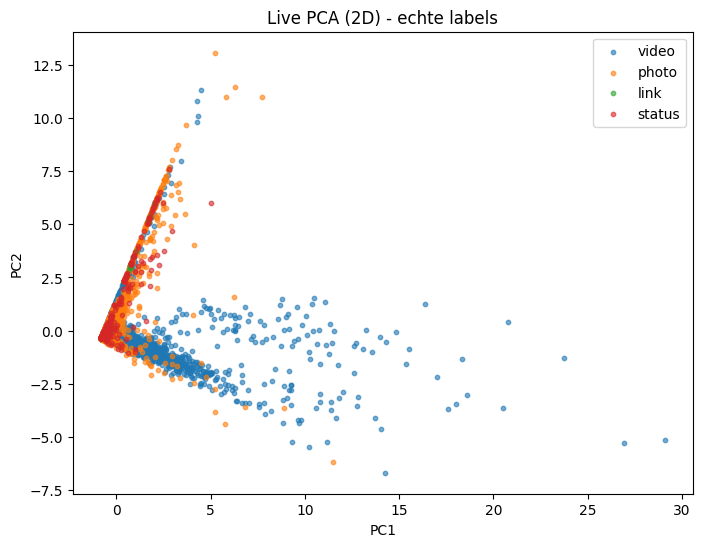

In [8]:
# Visualisatie in 2D, gekleurd volgens het echte label
pca_2 = PCA(n_components=2)
X_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

for label in y.unique():
    mask = y == label
    plt.scatter(X_2[mask, 0], X_2[mask, 1], s=10, label=label, alpha=0.6)
    
plt.title("Live PCA (2D) - echte labels")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

In de 2D-plot zie je al dat de labels sterk overlappen: de meeste posts zitten samen in één dichte wolk bij weinig interactie. Dat maakt het moeilijk voor clustering.

## 5. Algoritme 1: KMeans

Ik kies **KMeans** omdat het snel is, goed werkt op gestandaardiseerde PCA-data, en we het aantal clusters zelf kunnen kiezen. Ik zoek een goede `k` met de **elbow-methode** (inertia) en de **silhouette score**.

Beste k volgens silhouette: 2 (score 0.816)


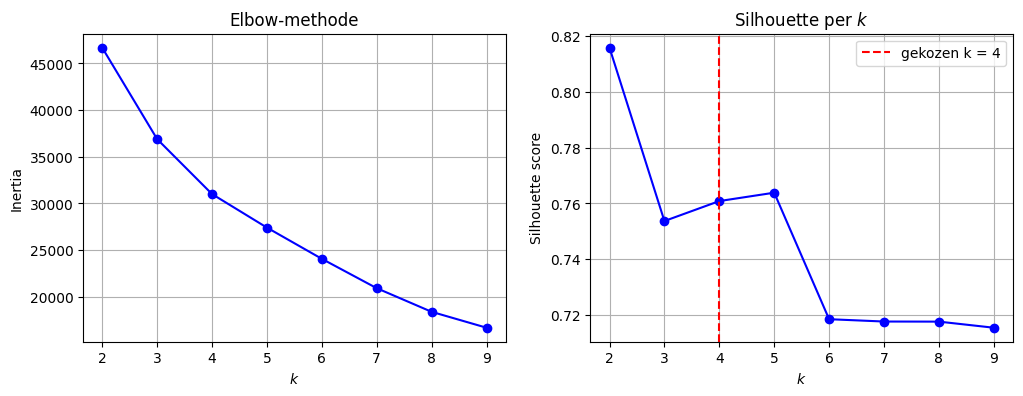

In [9]:
k_range = list(range(2, 10))
inertias = []
sil_scores = []
best_sil = -1.0
best_k = 2

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertias.append(kmeans.inertia_)
    sil = silhouette_score(X_pca, kmeans.labels_)
    sil_scores.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k = k

print(f"Beste k volgens silhouette: {best_k} (score {best_sil:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, "bo-")
axes[0].set_xlabel("$k$")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow-methode")
axes[0].grid()

axes[1].plot(k_range, sil_scores, "bo-")
axes[1].axvline(4, color="red", linestyle="--", label="gekozen k = 4")
axes[1].set_xlabel("$k$")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette per $k$")
axes[1].grid()
axes[1].legend()
plt.show()

**Keuze van k**: de silhouette is het hoogst bij k=2, maar met 2 clusters kan je nooit 4 labels reproduceren. Bij k=4 blijft de silhouette nog hoog, en er zijn precies **4 status_types** (link, photo, status, video). Daarom kies ik **k=4**.

In [10]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans_clusters = kmeans.fit_predict(X_pca)

print(f"Silhouette KMeans (k=4): {silhouette_score(X_pca, kmeans_clusters):.3f}")

Silhouette KMeans (k=4): 0.761


## 6. Algoritme 2: DBSCAN

Ik probeer ook **DBSCAN** omdat het geen vast aantal clusters nodig heeft en goed omgaat met **outliers** (ruis = label -1). Deze dataset heeft veel uitschieters (virale posts). Ik probeer verschillende `eps` en `min_samples` en kies de combinatie met de hoogste silhouette score.

In [11]:
dbscan_params = [(0.3, 5), (0.3, 10), (0.5, 5), (0.5, 10),
                 (0.7, 5), (0.7, 10), (1.0, 5), (1.0, 10)]
best_sil_db = -1.0
best_params = None

for eps, min_samples in dbscan_params:
    dbscan = DBSCAN(eps=eps, min_samples=min_samples).fit(X_pca)
    labels = dbscan.labels_
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)

    if len(set(labels)) >= 2:
        sil = silhouette_score(X_pca, labels)
        print(f"eps={eps}, min_samples={min_samples}: {n_clusters} clusters, "
              f"{n_noise} ruispunten, silhouette={sil:.3f}")
        if sil > best_sil_db:
            best_sil_db = sil
            best_params = (eps, min_samples)

print(f"Beste parameters: {best_params} (silhouette {best_sil_db:.3f})")

eps=0.3, min_samples=5: 16 clusters, 980 ruispunten, silhouette=0.035
eps=0.3, min_samples=10: 4 clusters, 1174 ruispunten, silhouette=0.053
eps=0.5, min_samples=5: 14 clusters, 659 ruispunten, silhouette=0.230
eps=0.5, min_samples=10: 7 clusters, 771 ruispunten, silhouette=0.261
eps=0.7, min_samples=5: 4 clusters, 515 ruispunten, silhouette=0.499
eps=0.7, min_samples=10: 4 clusters, 576 ruispunten, silhouette=0.476
eps=1.0, min_samples=5: 9 clusters, 360 ruispunten, silhouette=0.531
eps=1.0, min_samples=10: 2 clusters, 437 ruispunten, silhouette=0.530
Beste parameters: (1.0, 5) (silhouette 0.531)


In [12]:
dbscan = DBSCAN(eps=best_params[0], min_samples=best_params[1])
dbscan_clusters = dbscan.fit_predict(X_pca)

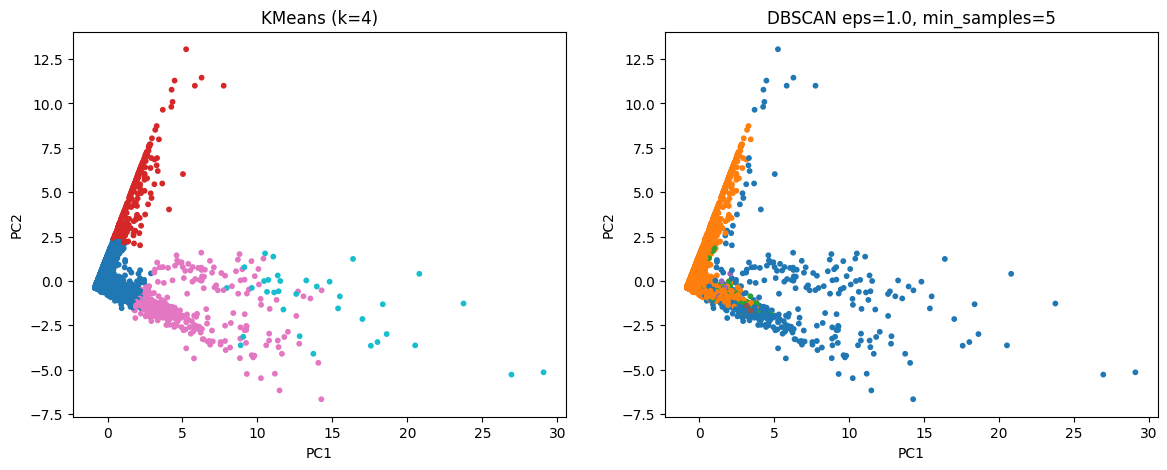

In [13]:
# Beide clusteringen naast elkaar in 2D
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(X_2[:, 0], X_2[:, 1], c=kmeans_clusters, s=10, cmap="tab10")
axes[0].set_title("KMeans (k=4)")
axes[1].scatter(X_2[:, 0], X_2[:, 1], c=dbscan_clusters, s=10, cmap="tab10")
axes[1].set_title(f"DBSCAN eps={best_params[0]}, min_samples={best_params[1]}")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.show()

**Keuze tussen de twee**: DBSCAN haalt een lagere silhouette dan KMeans, vindt een ander aantal clusters dan 4 en steekt bijna alle posts in één grote cluster. Omdat we 4 labels willen reproduceren, is **KMeans met k=4** hier de betere keuze.

## 7. Vergelijken met `status_type`

Clusternummers hebben geen vaste betekenis (cluster 0 is niet automatisch "link"). Daarom kijk ik per echt label (rij) in welke clusters (kolommen) de posts terechtkomen. `LabelEncoder` zet de tekstlabels om naar getallen zodat `confusion_matrix` ze kan vergelijken met de clusternummers.

{0: 'link', 1: 'photo', 2: 'status', 3: 'video'}


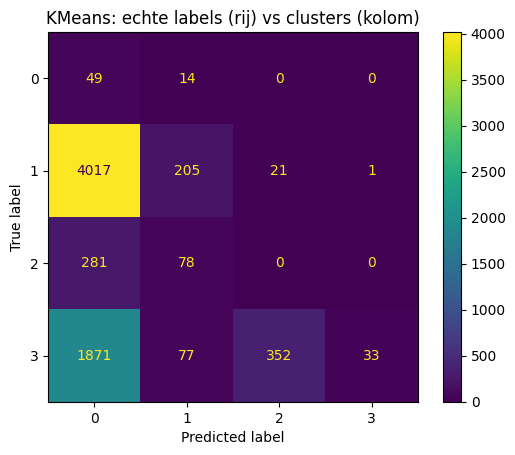

In [14]:
label_encoder = LabelEncoder()
y_true = label_encoder.fit_transform(y)
print(dict(enumerate(label_encoder.classes_)))

cm = confusion_matrix(y_true, kmeans_clusters)
ConfusionMatrixDisplay(cm).plot()
plt.title("KMeans: echte labels (rij) vs clusters (kolom)")
plt.show()

In [15]:
# Dezelfde tabel, maar met de namen van de labels
pd.crosstab(y, kmeans_clusters, rownames=["status_type"], colnames=["cluster"])

cluster,0,1,2,3
status_type,,,,
link,49,14,0,0
photo,4017,205,21,1
status,281,78,0,0
video,1871,77,352,33


In [16]:
pd.crosstab(y, dbscan_clusters, rownames=["status_type"], colnames=["cluster"])

cluster,-1,0,1,2,3,4,5,6,7,8
status_type,,,,,,,,,,
link,0,63,0,0,0,0,0,0,0,0
photo,61,4160,9,0,6,0,0,4,4,0
status,9,346,3,0,0,0,0,1,0,0
video,290,1837,175,5,1,7,13,0,2,3


## 8. Conclusie

- **De clusters komen slecht overeen met `status_type`.** Bij KMeans zit het grootste deel van alle types (photo, video, status, link) samen in cluster 0.
- **Video wordt nog het best herkend**: de kleinere clusters bestaan bijna volledig uit video's. Video's krijgen meer comments en shares, en dat patroon vindt KMeans wel.
- **Link en status** vormen nergens een eigen cluster. Ze zijn ook veel kleiner (63 en 359 posts) en gaan op in de grote groep.
- **Waarom?** De features meten alleen *hoeveel interactie* een post krijgt, niet *wat voor post* het is. Een foto en een link met weinig likes lijken voor het algoritme hetzelfde. De clustering groepeert dus op populariteit, niet op type.
- **DBSCAN** zet nog meer posts in één grote cluster en markeert de virale posts als ruis. Dat is nuttig om outliers te vinden, maar niet om de 4 types te reproduceren.